<a href="https://colab.research.google.com/github/M-AyyanAsif/NETSOL_TASKS/blob/main/1A_ml_optimization_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 ML Optimization Lab (Autograded)

This lab covers:
- Gradient Descent vs Adam
- Real dataset (synthetic regression)
- Loss functions
- Contour plots
- Autograded exercises


In [9]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

## 📦 Dataset (Synthetic Linear Regression)

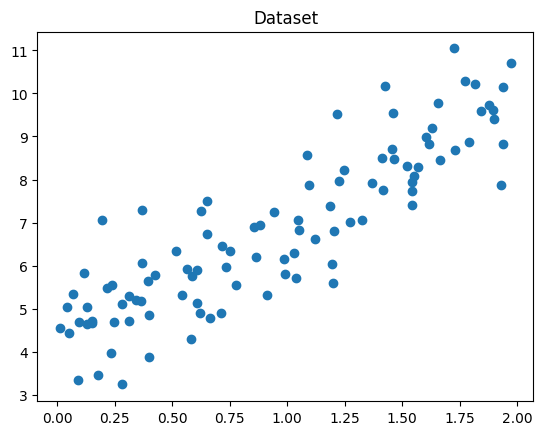

In [10]:
# Generate dataset
X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1)

plt.scatter(X, y)
plt.title('Dataset')
plt.show()

## 📉 Loss Function (MSE)

In [11]:
def compute_loss(theta, X, y):
    m = len(y)
    predictions = X.dot(theta)
    return (1/(2*m)) * np.sum((predictions - y)**2)

## ⚙️ Gradient Descent

In [12]:
def gradient_descent(X, y, lr=0.1, n_iters=100):
    m = len(y)
    theta = np.random.randn(2,1)
    X_b = np.c_[np.ones((m,1)), X]
    history = []

    for _ in range(n_iters):
        gradients = (1/m) * X_b.T.dot(X_b.dot(theta) - y)
        theta = theta - lr * gradients
        history.append(theta.copy())

    return theta, history

## ⚡ Adam Optimizer

In [13]:
def adam(X, y, lr=0.1, n_iters=100, beta1=0.9, beta2=0.999, eps=1e-8):
    m = len(y)
    theta = np.random.randn(2,1)
    X_b = np.c_[np.ones((m,1)), X]
    m_t, v_t = np.zeros_like(theta), np.zeros_like(theta)
    history = []

    for t in range(1, n_iters+1):
        grad = (1/m) * X_b.T.dot(X_b.dot(theta) - y)

        m_t = beta1*m_t + (1-beta1)*grad
        v_t = beta2*v_t + (1-beta2)*(grad**2)

        m_hat = m_t / (1-beta1**t)
        v_hat = v_t / (1-beta2**t)

        theta -= lr * m_hat / (np.sqrt(v_hat) + eps)
        history.append(theta.copy())

    return theta, history

## 📈 Contour Plot

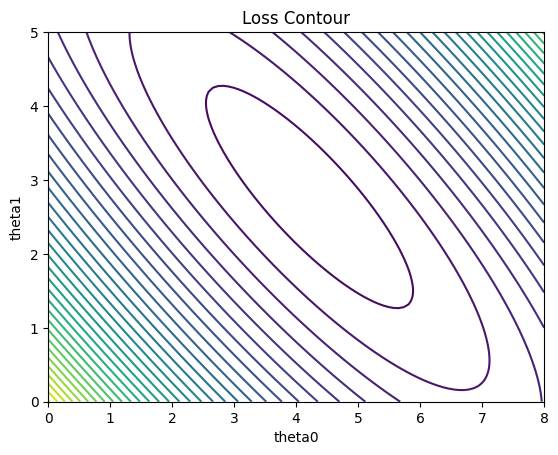

In [14]:
theta0_vals = np.linspace(0, 8, 100)
theta1_vals = np.linspace(0, 5, 100)

loss_vals = np.zeros((100,100))
X_b = np.c_[np.ones((len(X),1)), X]

for i, t0 in enumerate(theta0_vals):
    for j, t1 in enumerate(theta1_vals):
        theta = np.array([[t0],[t1]])
        loss_vals[i,j] = compute_loss(theta, X_b, y)

T0, T1 = np.meshgrid(theta0_vals, theta1_vals)

plt.contour(T0, T1, loss_vals.T, levels=30)
plt.title('Loss Contour')
plt.xlabel('theta0')
plt.ylabel('theta1')
plt.show()

## 🧪 Optimization Comparison

In [15]:
theta_gd, hist_gd = gradient_descent(X, y)
theta_adam, hist_adam = adam(X, y)

print('GD Theta:', theta_gd)
print('Adam Theta:', theta_adam)

GD Theta: [[3.90668931]
 [3.04241987]]
Adam Theta: [[3.26608382]
 [3.62173489]]


## ✅ Autograded Exercise

In [16]:
# STUDENT TASK
# Implement gradient function

def student_gradient(theta, X, y):
    m = len(y)
    # Compute the gradient of MSE loss
    gradients = (1/m) * X.T.dot(X.dot(theta) - y)
    return gradients


# AUTOGRADER
def test_gradient():
    theta = np.array([[1],[1]])
    X_b = np.c_[np.ones((len(X),1)), X]
    correct = (1/len(y)) * X_b.T.dot(X_b.dot(theta) - y)
    student = student_gradient(theta, X_b, y)

    if student is None:
        print('❌ Not implemented')
    elif np.allclose(student, correct):
        print('✅ Correct!')
    else:
        print('❌ Incorrect')

test_gradient()

✅ Correct!
